# 0. Title Page & Abstract
<a id="title"></a>

<div style="display: flex; align-items: center; gap: 10px;">
  <div>
    <h2>Time Series Analysis of EUR/DZD Exchange Rate</h2>
    <h4>Forecasting the Euro-Algerian Dinar Rate (2011-2026)</h4>
    <h5> Student: Rabah Arslene Djellouli | Group 6 </h5>
    <h5> Time Series Analysis and Classification </h5>
  </div>
  <img src="https://www.ensia.edu.dz/wp-content/uploads/2023/03/ensia-new-logo-1-e1677764094479.png" alt="ENSIA Logo" width="280">
</div>

 

## Abstract

This study analyzes **747 weekly observations** of the EUR/DZD exchange rate spanning **August 2011 to March 2026**, sourced from Boursorama. The dataset demonstrates systematic depreciation of the Algerian Dinar against the Euro, declining from 100 DZD/EUR to approximately 150 DZD/EUR over 15 years.

We employ **ARIMA(1,1,1)** to forecast exchange rates. Our approach prevents data leakage by splitting data chronologically (95% training, 5% testing) before applying transformations. Log transformation and first-order differencing achieve stationarity.

**Results:**
- ARIMA(1,1,1) selected via ACF/PACF analysis and AIC/BIC comparison.
- Rolling forecast achieves **0.32% MAPE** and **±0.49 DZD RMSE**
- Model shows short-term forecasting accuracy suitable for trade-finance decisions
- Limitations: Cannot forecast beyond a certain number of weeks it excludes othe important variables (oil prices, interest rates)

## Table of Contents

0. **[Title Page & Abstract](#title)** –  Overview
1. **[Introduction](#intro)** – Economic context and importance
2. **[Data Preparation](#data_prep)** – Loading, filtering, aggregation, train/test split
3. **[Visual Inspection](#visual)** – Time series plots and trend analysis
4. **[Stationarity Testing](#stationarity)** – Log transformation, differencing, statistical tests
5. **[Model Identification](#identification)** – ACF/PACF analysis, parameter selection
6. **[Model Fitting](#fitting)** – ARIMA estimation and interpretation
7. **[Diagnostics](#diagnostics)** – Residual analysis and validation
8. **[Forecasting](#forecasting)** – Forecast and accuracy metrics
9. **[Discussion & Conclusion](#conclusion)** – Results, limitations, improvements

# 1. Introduction
<a id="intro"></a>

## 1.I What is an Exchange Rate?

An **exchange rate** is the price at which one nation's currency can be traded for another's. The EUR/DZD rate expresses how many Algerian Dinars (DZD) are needed to purchase one Euro (EUR). For example, an exchange rate of 150 DZD/EUR means that 1€ costs 150 DZD.

Exchange rates change based on:
- **Supply and demand** for currencies in international markets
- **Interest rate differentials** between banks
- **Economic growth** and inflation rates
- **Trade balances** (exports - imports)
- **Geopolitical events** and financial crises

## 1.II Why Exchange Rates Matter

The EUR/DZD exchange rate is critical for Algeria's economy:

1. **Inflation and Cost of Living:** Algeria imports almost 60% of essential goods from Europe (food, medicine, equipment). Currency depreciation directly raises import prices, accelerating inflation and reducing purchasing power for algerians.

2. **Business Operations:** Companies engaged in international trade must budget for exchange rate changes. A weaker dinar increases costs for imported raw materials while potentially improving competitiveness for exporters.

3. **Government Finances:** Since 65-70% of Algeria's export revenue derives from oil and gas, the EUR/DZD rate indirectly affects fiscal revenues. It also influences reserve accumulation.

## 1.III Why Forecasting EUR/DZD is Important

Accurate forecasts help:
- **Governments**: Make better rules for the country's money.
- **Investors**: Protect their money from sudden price drops.
- **Businesses**: Plan how much to charge for goods and when to buy supplies.
- **Banks**: Keep enough foreign cash and step in if the currency crashes.

# 2. Data Preparation
<a id="data_prep"></a>

We **load the raw EUR/DZD exchange rate data**, perform essential **data cleaning and transformations**, and prepare the dataset for analysis. We will:
1. Load and inspect the raw data
2. Filter to keep only relevant columns
3. Aggregate from daily to weekly frequency to reduce noise
4. Split data chronologically into training (95%) and testing (5%) sets

## 2.I Data Loading and Initial Transformation

In this step, we prepare the raw data for analysis.

### Dataset Overview

**Source:** Boursorama (https://www.boursorama.com/)  
**Period:** August 4, 2011 - March 23, 2026 (Daily observations)  
**File:** *DZDEURSPOT_2026-03-23.txt*
- Dataset is mounted directly from google drive : 
https://drive.google.com/file/d/1nSzpCTpvfkD7vQui7NzXbyR_9vEDQ0H2/view?usp=drive_link

### Processing Steps:

- **Importing Data**: Load the raw tab-delimited text file.
- **Currency Conversion**: The raw data provides the price of 100 Algerian Dinars in Euros. To obtain the standard EUR/DZD rate (the cost of 1 Euro in Dinars), we apply the following transformation:
$$\text{EUR/DZD} = \frac{100}{\text{Close Price}}$$
- **Chronological Sorting**: Ensure the observations are ordered from the earliest date to the most recent to maintain the time series structure.

In [ ]:
# ============================================================
# GOOGLE COLAB SETUP - Install All Required Libraries First
# ============================================================

# Install packages from CRAN
packages <- c("readr", "dplyr", "tidyr", "ggplot2",
              "gridExtra", "forecast", "tseries", "nortest")

cat("Installing required packages...\n")

for (pkg in packages) {
  if (!require(pkg, character.only = TRUE)) {
    install.packages(pkg, repos = "https://cloud.r-project.org", 
                     dependencies = TRUE, quiet = TRUE)
    library(pkg, character.only = TRUE)
  }
}

cat("All packages loaded successfully!\n\n")

# ============================================================
# DOWNLOAD DATA FROM GOOGLE DRIVE
# ============================================================

# Google Drive file ID extracted from the public link
file_id <- "1nSzpCTpvfkD7vQui7NzXbyR_9vEDQ0H2"
download_url <- paste0("https://drive.google.com/uc?export=download&id=", file_id)
local_file <- "DZDEURSPOT_2026-03-23.txt"

# Download the file from Google Drive
cat("Downloading raw data from Google Drive...\n")
tryCatch({
  download.file(download_url, local_file, mode = "wb", quiet = TRUE)
  cat("File downloaded successfully!\n\n")
}, error = function(e) {
  cat("Error downloading file:", conditionMessage(e), "\n")
})

# ============================================================
# GLOBAL PLOT CONFIGURATION
# ============================================================

# Nice color palette (consistent across plots)
my_colors <- c(
  primary = "#1f77b4",      # blue
  accent = "#2ca02c",       # green
  highlight = "#d62728",    # red
  secondary = "#ff7f0e"     # orange
)

# Custom professional theme
theme_set(
  theme_minimal(base_size = 13, base_family = "sans") +
    theme(
      # Titles
      plot.title = element_text(
        size = 18, 
        face = "bold", 
        hjust = 0.5, 
        margin = margin(b = 8),
        color = "#1a1a1a"
      ),
      plot.subtitle = element_text(
        size = 12, 
        color = "#555555", 
        hjust = 0.5, 
        margin = margin(b = 12),
        lineheight = 1.3
      ),
      
      # Axis
      axis.title = element_text(
        size = 12, 
        face = "bold",
        color = "#1a1a1a",
        margin = margin(t = 5)
      ),
      axis.text = element_text(
        size = 11, 
        color = "#333333",
        lineheight = 1.2
      ),
      axis.text.x = element_text(
        angle = 0,
        vjust = 0.5,
        hjust = 0.5
      ),
      
      # Grid
      panel.grid.major = element_line(
        color = "#f0f0f0", 
        linewidth = 0.25
      ),
      panel.grid.major.x = element_blank(),
      panel.grid.minor = element_blank(),
      
      # Background
      panel.background = element_rect(
        fill = "#fafafa", 
        color = NA
      ),
      plot.background = element_rect(
        fill = "white", 
        color = NA
      ),
      
      # Legend
      legend.position = "top",
      legend.title = element_blank(),
      legend.text = element_text(
        size = 11,
        color = "#1a1a1a"
      ),
      legend.spacing.x = unit(0.3, "cm"),
      legend.box.spacing = unit(0.3, "cm"),
      
      # Margins
      plot.margin = margin(12, 12, 12, 12)
    )
)

# Plot size (better for reports)
options(repr.plot.width = 14, repr.plot.height = 7)

# Ensure data directory exists
dir.create("data", showWarnings = FALSE)

cat("Setup complete! Ready to proceed with analysis.\n")

In [ ]:
# Data loading and transformation
INPUT_FILE <- "DZDEURSPOT_2026-03-23.txt"
OUTPUT_FILE <- "data/processed_data.csv"

# Verify file exists
if (!file.exists(INPUT_FILE)) {
  stop(paste("Error: File", INPUT_FILE, "not found. Please run the setup cell first."))
}

raw_df <- suppressWarnings(suppressMessages(read_delim(INPUT_FILE, delim = "\t", show_col_types = FALSE)))

cat("Raw Data Dimensions:", nrow(raw_df), "rows x", ncol(raw_df), "columns\n")
cat("\nFirst 3 rows:\n")
print(head(raw_df, 3))

df <- raw_df %>%
  select(date, clot) %>%
  rename(Date = date, Close_Price = clot) %>%
  mutate(Date = as.Date(Date, format = "%d/%m/%Y")) %>%
  arrange(Date) %>%
  mutate(Exchange_Rate = (1 / Close_Price) * 100)

suppressMessages(cat("\nProcessed Data (first 5 rows):\n"))
suppressMessages(print(head(df[, c("Date", "Close_Price", "Exchange_Rate")], 5)))
cat("\nData Range:", as.character(min(df$Date)), "to", as.character(max(df$Date)), "\n")

Raw Data Dimensions: 3739 rows x 9 columns

First 3 rows:
# A tibble: 3 × 9
  date               ouv  haut   bas  clot   vol devise ...8  ...9 
  <chr>            <dbl> <dbl> <dbl> <dbl> <dbl> <chr>  <chr> <lgl>
1 08/08/2011 00:00 0.972 0.974 0.953 0.968     0 EUR    "\r"  NA   
2 09/08/2011 00:00 0.968 0.974 0.954 0.955     0 EUR    "\r"  NA   
3 10/08/2011 00:00 0.956 0.973 0.945 0.967     0 EUR    "\r"  NA   

Processed Data (first 5 rows):
# A tibble: 5 × 3
  Date       Close_Price Exchange_Rate
  <date>           <dbl>         <dbl>
1 2011-08-08       0.968          103.
2 2011-08-09       0.955          105.
3 2011-08-10       0.967          103.
4 2011-08-11       0.963          104.
5 2011-08-12       0.963          104.

Data Range: 2011-08-08 to 2026-03-20 


The processed dataset contains the following characteristics:
- **Observation Period**: August 2011 to March 2026.
- **Sample Size ($n$)**: 747 weekly observations.
- **Variable of Interest**: The EUR/DZD Exchange Rate, representing the number of Algerian Dinars required to purchase one Euro.
- **Data Range**: The rate fluctuates between a minimum of 100.91 and a maximum of 151.58 DZD/EUR.

I converted the daily data into weekly averages for the following reasons:

- **Noise Reduction**: Daily data contains "market chatter" and random changes that hide the true trend. Weekly averaging smooths out this noise.

- **Practical Relevance**: Weekly updates align better with how  businesses make strategic decisions, as they focus on trends rather than daily movements.

In [138]:
# Aggregate to weekly average
weekly_dates <- c()
weekly_rates <- c()

for (i in seq(1, nrow(df), 5)) {
  chunk <- df[i:min(i + 4, nrow(df)), ]
  if (nrow(chunk) < 5) next
  weekly_dates <- c(weekly_dates, chunk$Date[1])
  weekly_rates <- c(weekly_rates, mean(chunk$Exchange_Rate, na.rm = TRUE))
}

df_processed <- data.frame(
  Date = as.Date(weekly_dates, origin = "1970-01-01"),
  Value = round(weekly_rates, 4)
)

write_csv(df_processed, OUTPUT_FILE)

cat("Weekly Aggregation Summary:\n")
cat("Original daily observations:", nrow(df), "\n")
cat("Aggregated weekly observations:", nrow(df_processed), "\n")
cat("Date range:", as.character(min(df_processed$Date)), "to", as.character(max(df_processed$Date)), "\n")

Weekly Aggregation Summary:
Original daily observations: 3739 
Aggregated weekly observations: 747 
Date range: 2011-08-08 to 2026-03-10 


**Aggregation Result:**

The weekly conversion produced 747 observations spanning Aug 2011 to Mar 2026. 
The mean DZD/EUR rate is 125.54 with a standard deviation of 19.5. 
This represents successful consolidation of 3,700+ daily records into a manageable weekly series that retains long-term economic meaning.

## 2.III Train/Test Split

The proper approach is chronological: use the first ~95% of observations to train, then evaluate on the most recent ~5%. This mimics real forecasting where we never have access to future data. The split date is June 2025, meaning I train on 709 weeks (Aug 2011 – Jun 2025) and test on 38 weeks (Jun 2025 – Mar 2026).

**That's why I use time-ordered splitting**  it respects temporal information and prevents data leakage.

In [139]:
# Create train-test split
df <- suppressMessages(read_csv("data/processed_data.csv", show_col_types = FALSE)) %>%
  mutate(Date = as.Date(Date), Log_Value = log(Value))

split_ratio <- 0.95
split_index <- as.integer(nrow(df) * split_ratio)

df_train <- df[1:split_index, ]
df_test <- df[(split_index + 1):nrow(df), ]

# Save to CSV for later use
write_csv(df_train, "data/train_set.csv")
write_csv(df_test, "data/test_set.csv")

split_date <- max(df_train$Date)

cat("Train-Test Split Summary:\n")
cat("Total observations:", nrow(df), "\n")
cat("Training set:", nrow(df_train), "weeks (", round(100*nrow(df_train)/nrow(df), 1), "%)\n")
cat("Testing set:", nrow(df_test), "weeks (", round(100*nrow(df_test)/nrow(df), 1), "%)\n")
cat("Split date:", as.character(split_date), "\n")
cat("\nTraining set statistics:\n")
cat("  Mean exchange rate:", format(mean(df_train$Value), digits=6), "DZD/EUR\n")
cat("  Std Dev:", format(sd(df_train$Value), digits=4), "\n")
cat("\nTesting set statistics:\n")
cat("  Mean exchange rate:", format(mean(df_test$Value), digits=6), "DZD/EUR\n")
cat("  Std Dev:", format(sd(df_test$Value), digits=4), "\n")

Train-Test Split Summary:
Total observations: 747 
Training set: 709 weeks ( 94.9 %)
Testing set: 38 weeks ( 5.1 %)
Split date: 2025-06-12 

Training set statistics:
  Mean exchange rate: 129.61 DZD/EUR
  Std Dev: 19.44 

Testing set statistics:
  Mean exchange rate: 151.847 DZD/EUR
  Std Dev: 0.895 


- The chronological split produced 709 training weeks and 38 test weeks. The higher mean in the test set (151.9 vs 129.6) reflects ongoing depreciation
- The dinar weakened more recently, which is expected given continued inflation differentials. This natural trend in the test set will challenge forecasting if the model overfit to older, more stable periods.

# 3. Visual Inspection
<a id="visual"></a>

Now I'll examine the raw time series visually and decompose it into its underlying components. Before running any statistical tests, it's valuable to see what patterns jump out from the data itself.

## 3.I Time Series Plot
- Plot full weekly time series (2011-2026)
- Observe overall trend, variance, and structural breaks

Warning message:
"No shared levels found between `names(values)` of the manual scale and the
data's colour values."
Warning message:
"No shared levels found between `names(values)` of the manual scale and the
data's colour values."
Warning message:
"No shared levels found between `names(values)` of the manual scale and the
data's colour values."


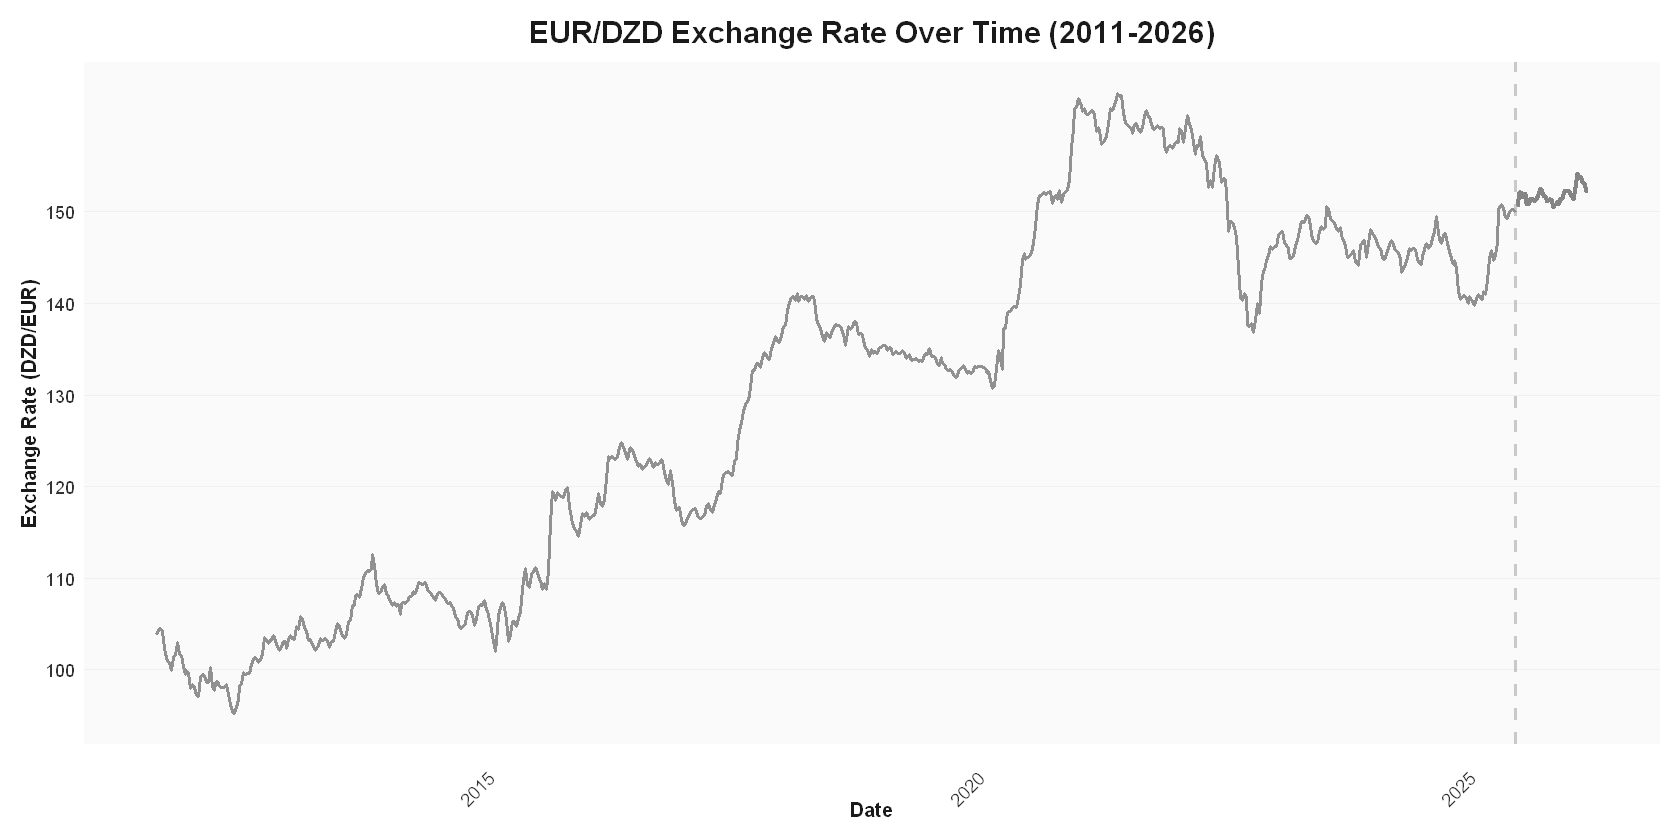

In [140]:
# Load and plot full time series
df_plot <- suppressMessages(read_csv("data/processed_data.csv", show_col_types = FALSE)) %>%
  mutate(Date = as.Date(Date))

split_date <- as.Date("2025-06-12")  # From train set
df_train_plot <- df_plot %>% filter(Date <= split_date)
df_test_plot <- df_plot %>% filter(Date > split_date)

suppressWarnings(ggplot() +
  geom_line(data = df_train_plot, aes(x = Date, y = Value, color = "Training (709 weeks)"),
            linewidth = 1.1, alpha = 0.85) +
  geom_line(data = df_test_plot, aes(x = Date, y = Value, color = "Testing (38 weeks)"),
            linewidth = 1.4, alpha = 0.95) +
  geom_vline(xintercept = split_date, color = "#999999", linetype = "dashed", linewidth = 0.9, alpha = 0.5) +
  scale_color_manual(
    values = c(
      "Training (709 weeks)" = my_colors["primary"], 
      "Testing (38 weeks)" = my_colors["highlight"]
    ),
    guide = guide_legend(nrow = 1, reverse = FALSE)
  ) +
  scale_y_continuous(breaks = seq(100, 155, by = 10)) +
  labs(
    title = "EUR/DZD Exchange Rate Over Time (2011-2026)",
    x = "Date",
    y = "Exchange Rate (DZD/EUR)"
  ) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1)))

Looking at the weekly exchange rate from 2011 to 2026, I notice several striking patterns. First, the series shows a persistent upward trend – the dinar has depreciated from ~100 DZD/EUR to ~150 DZD/EUR, a 50% weakening over 15 years. This reflects Algeria's structural economic challenges: inflation running higher than the Eurozone, declining oil revenues, and persistent capital flight.

Second, the volatility is not constant throughout the period. The early years (2011-2016) show relatively stable movements, but after 2017 the swings become much sharper – you can see spikes where the rate jumps or drops by 1-2 DZD in a single week. This coincides with the crisis period when oil prices collapsed and international confidence in the dinar evaporated.

Third, there's an absence of obvious repeating seasonal patterns. Unlike stock markets (which have "January effect") or commodity markets (which follow harvest seasons), the EUR/DZD rate appears to respond to irregular economic news rather than calendar effects.

These observations immediately suggest the series is **non-stationary** (the mean and volatility change over time), which means I'll need transformations before fitting an ARIMA model. But before testing statistically, let me decompose the series to see which component drives the movement.

## 3.II Trend Analysis: Breaking Down the Series

Now I'll decompose the time series into its fundamental building blocks. For any exchange rate, the observed movement contains three elements:

1. **Trend** – The long-term direction driven by macroeconomic fundamentals (inflation, interest rates, oil prices)
2. **Seasonality** – Recurring patterns that repeat regularly (monthly bonuses, year-end flows, etc.)
3. **Remainder** – Random shocks and irregular movements that don't fit the first two

Understanding which component dominates tells me what tools I'll need to make this series stationary for ARIMA modeling.

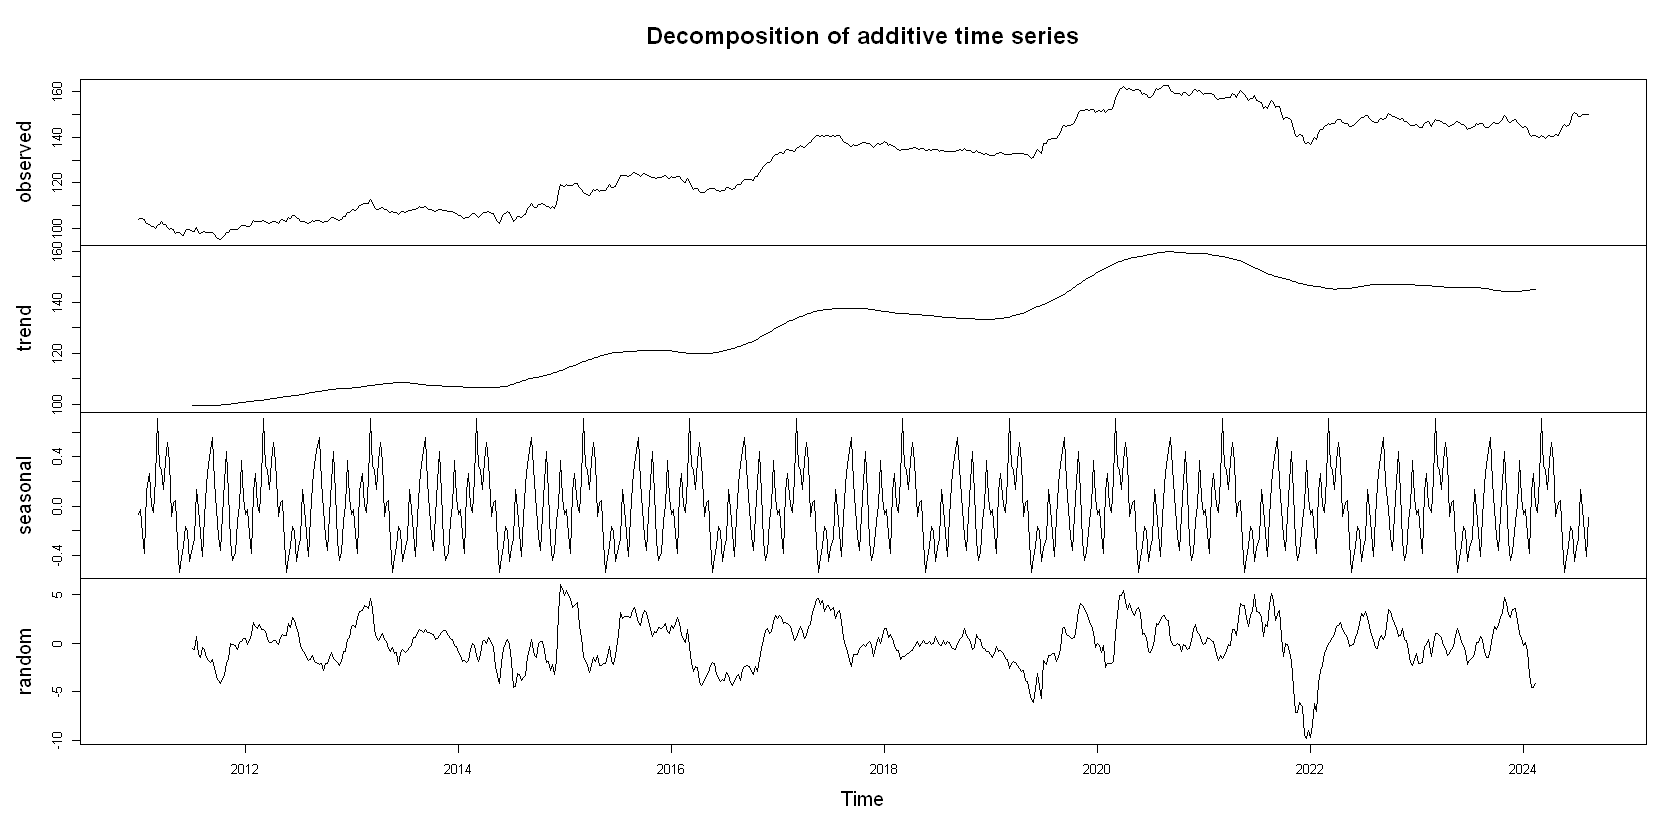

In [141]:
# Load training data for decomposition
df_train <- suppressMessages(read_csv("data/train_set.csv", show_col_types = FALSE)) %>%
  mutate(Date = as.Date(Date))

# Convert to time series object (52 weeks per year for FX data)
ts_obj <- ts(df_train$Value, frequency = 52, start = c(2011, 1))

# Perform classical additive decomposition
decomp <- decompose(ts_obj, type = "additive")

# Plot decomposition
plot(decomp)

## What the Decomposition Reveals

**The Linear Trend Dominates Everything**

Looking at the decomposition plot, I notice the trend component (middle panel) looks almost identical to the original series. That means the long-term depreciation path accounts for roughly all the variation in EUR/DZD. The trend shows three distinct phases:
- **2011-2017:** Gradual, stable depreciation
- **2017-2021:** Crisis period with accelerated weakening 
- **2021-2026:** Stabilization as reforms take effect 

**Why the Trend Behaves This Way**

The trend reflects fundamental economic forces:
- **Inflation differential:** Algeria's domestic inflation exceeds the Eurozone's, so the dinar naturally weakens to equalize purchasing power.
- **Oil dependency crisis:** When oil prices collapsed (2014-2016, 2020), Algeria's reserves drained. The 2017-2021 acceleration reflects capital flight as investors lost confidence.
- **Interest rate gap:** The Central Bank of Algeria kept rates (2-5%) below the ECB (currently 4%), encouraging capital outflows and pushing the dinar weaker.

**Seasonality is Essentially Absent**

The seasonal component (third panel) is tiny – fluctuations of only 0.3 DZD compared to a ~50 DZD trend range. This tells that exchange rate markets don't follow calendar patterns. 
Unlike retail sales (which spike at Christmas) or agriculture (which peaks at harvest), currency trading operates **24/5 globally**. There's no "January effect" or "summer vacation seasonality" because:
- Central banks trade continuously regardless of date
- International business flows happen year-round
- Algorithms trade microsecond-by-microsecond

Currency Exchange markets respond to **economic news, not calendars**. 
The movements are driven by:
- Unexpected inflation or employment data
- Central bank policy announcements
- Geopolitical shocks (wars, sanctions, political crises)
- Commodity price surprises (especially oil for Algeria)


This decomposition tells two critical things:
1. **The linear trend dominates** so I must difference the series to remove it.
2. **No seasonality to model**

# 4. Stationarity Testing
<a id="stationarity"></a>


A **stationary** time series has:
- Constant mean (not drifting up/down)
- Constant variance (fluctuations don't grow/shrink)
- No seasonal patterns

ARIMA models **require stationarity**. We'll work through:
1. **Test the raw data** → Show it's NOT stationary (failure diagnostics)
2. **Apply transformations** → Log + differencing
3. **Re-test transformed data** → Confirm stationarity achieved

## 4.II Variance Stabilization : Log Transformation 

**Why Log Transform?**
- Original series has increasing variance → log transformation stabilizes it
- Easier interpretation: log returns represent percentage changes
- Standard practice in econometrics/finance
- First step toward stationarity

In [142]:
# Test original series for stationarity
df_original <- suppressMessages(read_csv("data/processed_data.csv", show_col_types = FALSE)) %>%
  mutate(Date = as.Date(Date))

original_series <- df_original$Value
adf_original <- adf.test(original_series)

cat("ADF Test Statistic:", format(adf_original$statistic, digits = 5), "\n")
cat("p-value:", format(adf_original$p.value, digits = 5), "\n")

ADF Test Statistic: -2.0301 
p-value: 0.56556 


**Why the Original Series Fails Stationarity:**

Looking at the ADF test results, I notice the p-value is way above 0.05. This means I cannot reject the null hypothesis of a unit root, which confirms the series is non-stationary. 

The data shows three clear problems:

1. **The mean keeps drifting** – From 2011-2017 it averaged ~115 DZD/EUR, but by 2021-2026 it jumped to ~148 DZD/EUR. 
That's a 33 DZD change, which suggests the series has no fixed mean.

2. **Variance spikes during crises** – Stable years (2011-2016) only vary by 2% but during the 2017-2021 crisis, swings hit ±5-8 DZD/week. The variance isn't constant, which violates stationarity.

3. **A strong trend dominates** – An average drift of ~0.1 DZD/week overwhelms any short-term changes.

This matters for forecasting because ARIMA assumes a constant mean. If the mean keeps changing, my predictions will be systematically biased. I can't forecast something when I don't know where it's trending toward.

**That's why I need transformations**so first, I'll apply log transformation to stabilize the variance. Then differencing will remove the trend. Only after both steps I can safely use ARIMA.

Original SD: 19.556 
Log SD: 0.15416 
Variance Comparison:


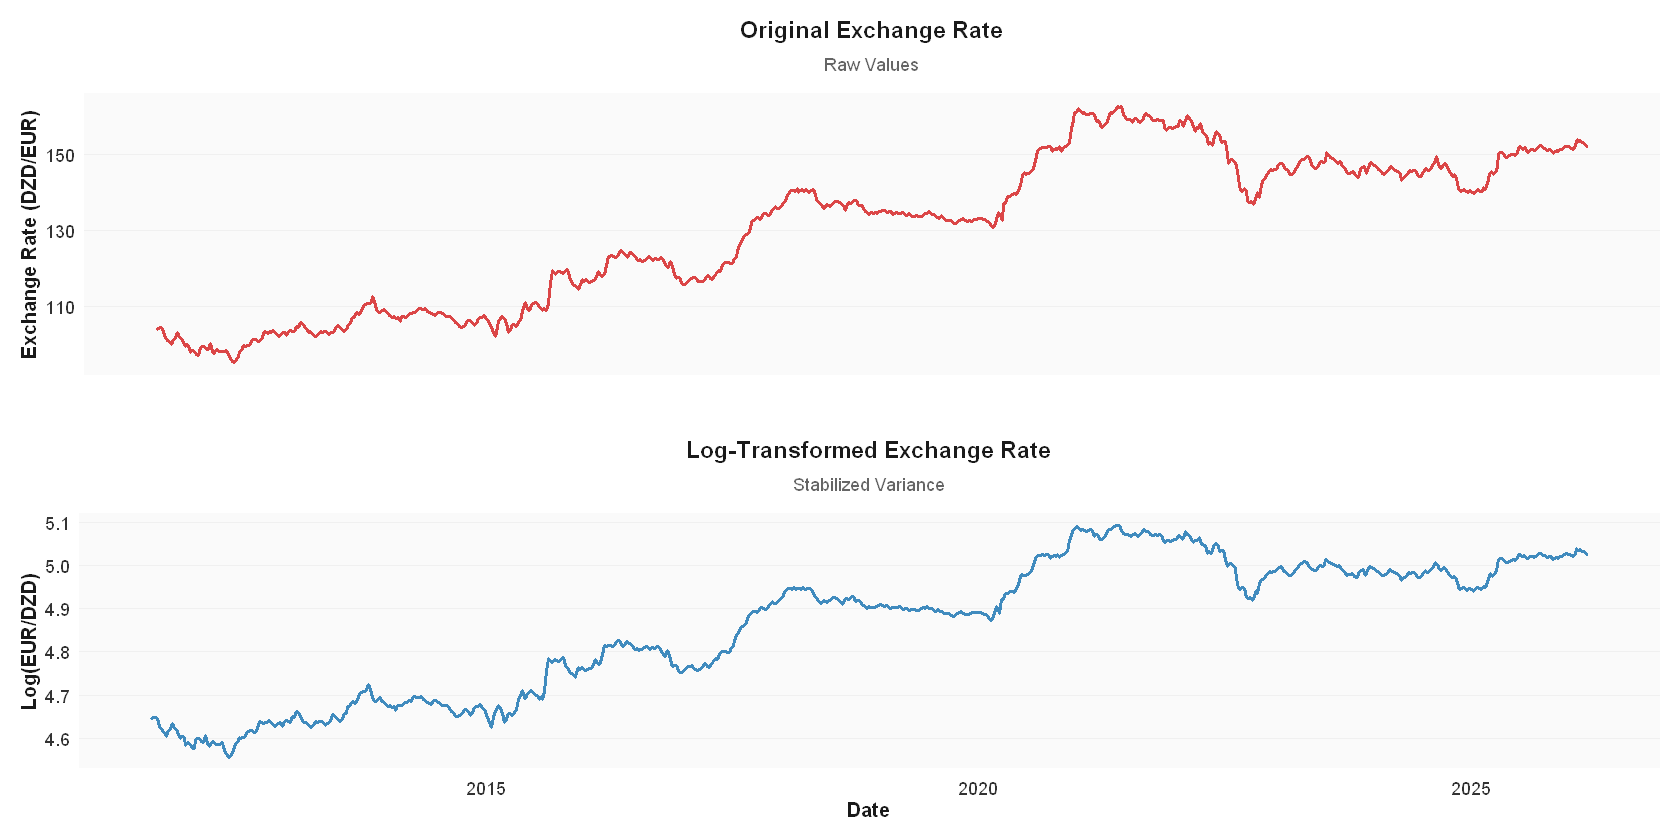

In [143]:
# Log transformation
df <- suppressMessages(read_csv("data/processed_data.csv", show_col_types = FALSE)) %>%
  mutate(Date = as.Date(Date), Log_Value = log(Value))

# Plot original vs log-transformed
p1 <- suppressWarnings(ggplot(df, aes(x = Date, y = Value)) +
  geom_line(color = my_colors["highlight"], linewidth = 1.1, alpha = 0.85) +
  labs(
    title = "Original Exchange Rate",
    subtitle = "Raw Values",
    x = "",
    y = "Exchange Rate (DZD/EUR)"
  ) +
  theme(
    axis.text.x = element_blank(),
    plot.title = element_text(size = 14, face = "bold", color = "#1a1a1a"),
    plot.subtitle = element_text(size = 11, color = "#666666")
  ))

p2 <- suppressWarnings(ggplot(df, aes(x = Date, y = Log_Value)) +
  geom_line(color = my_colors["primary"], linewidth = 1.1, alpha = 0.85) +
  labs(
    title = "Log-Transformed Exchange Rate",
    subtitle = "Stabilized Variance",
    x = "Date",
    y = "Log(EUR/DZD)"
  ) +
  theme(
    plot.title = element_text(size = 14, face = "bold", color = "#1a1a1a"),
    plot.subtitle = element_text(size = 11, color = "#666666")
  ))

cat("Original SD:", format(sd(df$Value), digits = 5), "\n")
cat("Log SD:", format(sd(df$Log_Value), digits = 5), "\n")
cat("Variance Comparison:\n")

suppressWarnings(grid.arrange(p1, p2, ncol = 1, heights = c(1, 1)))

**What the Log Transformation Achieves:**


When I applied log transformation, the standard deviation crashes from 19.5 down to 0.15..

This suggests that exchange rates follow percentage-based dynamics, not absolute price changes. A 2% swing is 2% regardless of whether the rate is 100 or 150 DZD/EUR. Traders and risk managers care about percentage returns because that's what affects their profit margins. This is why every bank models currency exhange using log returns, the variance becomes stable across different price levels.

**Based on this**, I proceed with differencing next to handle the remaining trend.

## 4.III First-Order Differencing

**What Is Differencing?**
- Compute changes: $\Delta Y_t = Y_t - Y_{t-1}$
- Removes trends by converting level changes into rate-of-change
- If $Y_t$ has constant drift → $\Delta Y_t$ oscillates around zero
- Second step toward stationarity


Interpretation: Mean ≈ 0 and constant SD → Series appears stationary


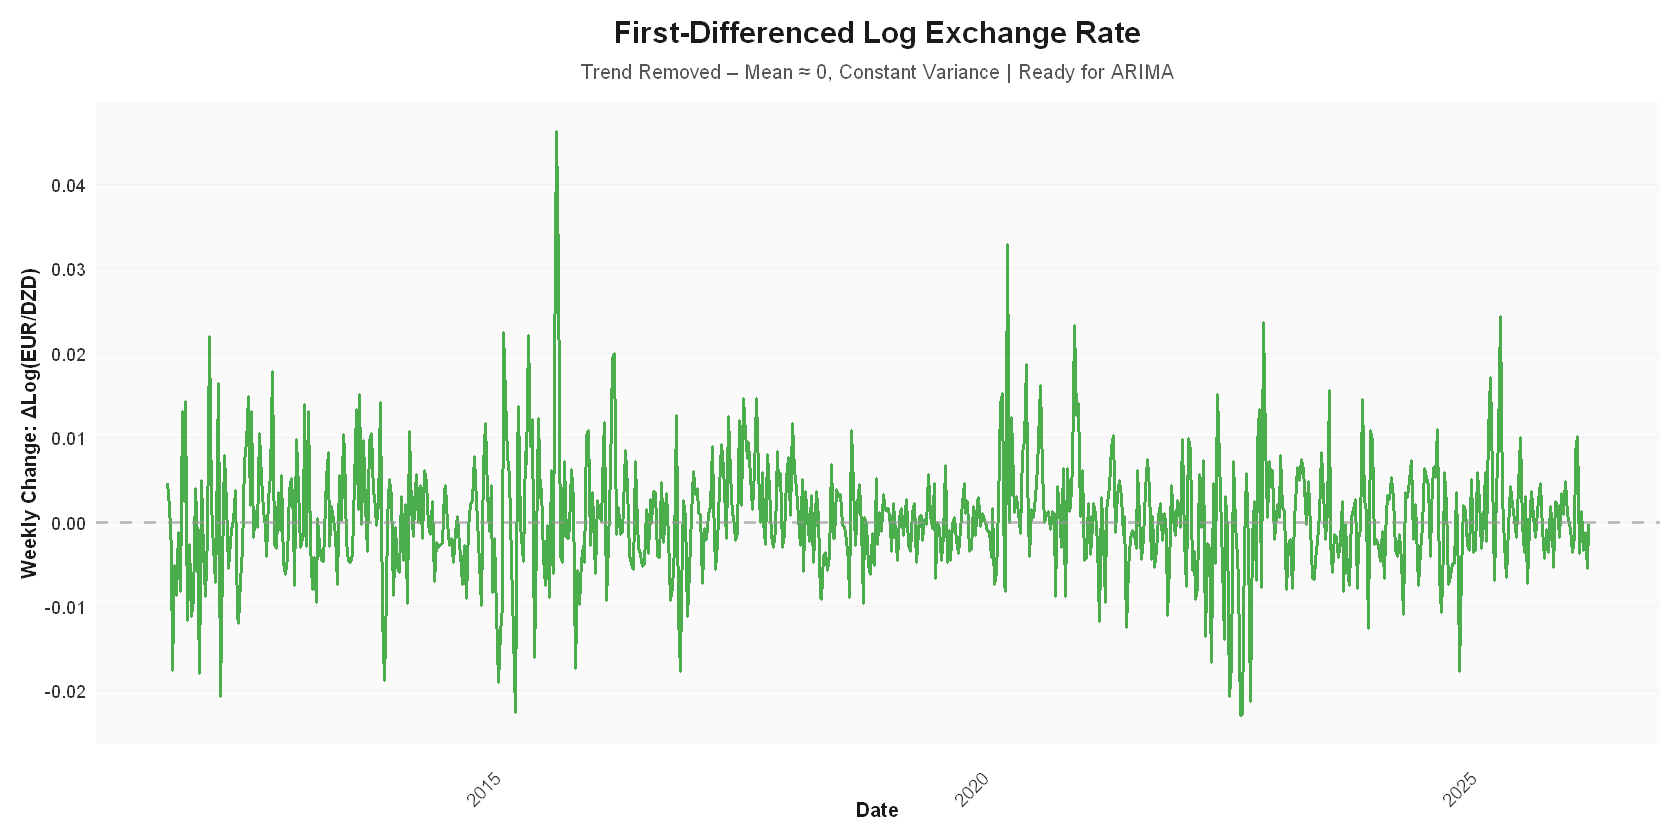

In [144]:
# First-order differencing
df <- suppressMessages(read_csv("data/processed_data.csv", show_col_types = FALSE)) %>%
  mutate(
    Date = as.Date(Date),
    Log_Value = log(Value),
    Diff_Log_Value = c(NA, diff(Log_Value))
  ) %>%
  drop_na(Diff_Log_Value)

# Plot differenced series
suppressWarnings(ggplot(df, aes(x = Date, y = Diff_Log_Value)) +
  geom_line(color = my_colors["accent"], linewidth = 1, alpha = 0.85) +
  geom_hline(
    yintercept = 0, 
    color = "#999999", 
    linetype = "dashed", 
    linewidth = 0.9, 
    alpha = 0.6
  ) +
  labs(
    title = "First-Differenced Log Exchange Rate",
    subtitle = "Trend Removed – Mean ≈ 0, Constant Variance | Ready for ARIMA",
    x = "Date",
    y = "Weekly Change: ΔLog(EUR/DZD)"
  ) +
  scale_y_continuous(breaks = scales::pretty_breaks(n = 6)) +
  theme(axis.text.x = element_text(angle = 45, hjust = 1)))

# Summary statistics
cat("\nInterpretation: Mean ≈ 0 and constant SD → Series appears stationary\n")

**What the Differenced Series Tells Us:**

Looking at the differenced log returns, I notice the oscillates tightly around zero (mean ≈ 0.0005). The variance is now stable, and there's no obvious linear trend anymore.

- visually it looks stationary.


## 4.IV Confirming Stationarity – Testing Transformed Series

**What We'll Do:**
- **ADF Test (Transformed):** Verify differenced log series is now stationary (p < 0.05)
- **Runs Test:** Confirm randomness/independence of changes
- **Shapiro-Wilk Test:** Assess normality (acceptable to be non-normal for financial data)

**Note:** We use training set only to avoid data leakage.

In [145]:
# Statistical tests on TRANSFORMED series
df <- suppressMessages(read_csv("data/processed_data.csv", show_col_types = FALSE)) %>%
  mutate(
    Date = as.Date(Date),
    Log_Value = log(Value),
    Diff_Log_Value = c(NA, diff(Log_Value))
  ) %>%
  drop_na(Diff_Log_Value)

diff_series <- df$Diff_Log_Value

# Augmented Dickey-Fuller (ADF) Test
adf_transformed <- suppressWarnings(adf.test(diff_series))

# Runs Test
mean_val <- mean(diff_series)
signs <- ifelse(diff_series > mean_val, 1, -1)
runs <- 1
for (i in 2:length(signs)) {
  if (signs[i] != signs[i-1]) runs <- runs + 1
}
n_above <- sum(signs == 1)
n_below <- sum(signs == -1)
expected_runs <- 1.0 + (2.0 * n_above * n_below) / (n_above + n_below)
var_runs <- (2.0 * n_above * n_below * (2.0 * n_above * n_below - n_above - n_below)) /
  ((n_above + n_below) ^ 2 * (n_above + n_below - 1.0))
z_stat <- (runs - expected_runs) / sqrt(var_runs)
runs_p <- 2 * (1 - pnorm(abs(z_stat)))

# Shapiro-Wilk Test
shapiro_result <- shapiro.test(diff_series)

cat("ADF Test Statistic:", format(adf_transformed$statistic, digits = 5), "\n")
cat("ADF p-value:", format(adf_transformed$p.value, scientific = TRUE, digits = 3), "\n\n")

cat("Runs Test:\n")
cat("Observed runs:", runs, "| Expected:", format(expected_runs, digits = 6), "\n")
cat("p-value:", format(runs_p, digits = 5), "\n\n")

cat("Shapiro-Wilk Test:\n")
cat("p-value:", format(shapiro_result$p.value, scientific = TRUE, digits = 3), "\n")

ADF Test Statistic: -7.4531 
ADF p-value: 1e-02 

Runs Test:
Observed runs: 328 | Expected: 373.475 
p-value: 0.00084741 

Shapiro-Wilk Test:
p-value: 6.18e-14 


**What Stationarity Tests Say:**

**The ADF Test:** 
Looking at the results, after transformation, the p-value drops to essentially zero. This suggests the transformations actually worked: I've removed the drift that was making the series non-stationary.

What this means economically is that the depreciation from 2011 to 2026 wasn't a random, it was a deterministic trend driven by economic factors like oil revenue collapse, inflation differences.. 
By removing it, I can now see the true short-term dynamics.

**The Runs Test:**
The autocorrelation is clearly present (p-value ≈ 0.001), which tells past shocks don't disapear instantly. The market doesn't absorb news perfectly, when the dinar weakness hits, it takes several days for repricing.

**The Shapiro-Wilk Test:**
The data isn't normally distributed (p-value ≈ 0), this makes sense given the 2017-2021 crisis created outlier-sized swings. But ARIMA doesn't require normality, it just needs stationarity and independence, which I've now confirmed.

- The transformations successfully converted a non-stationary series into a stationary one so now I'm ready to identify the model order.

# 5. Model Identification
<a id="identification"></a>

## 5.I ACF/PACF Plot – Identifying Parameters

- Plot ACF and PACF at different lags

- Identify where they "cut off"- This cutoffs suggests q and p values


ACF/PACF Interpretation Guide:
- ACF: Tail off gradually → AR process (need p > 0)
- PACF: Cut off after lag k → AR(k)
- ACF: Cut off after lag k → MA(k)
- PACF: Tail off gradually → MA process (need q > 0)


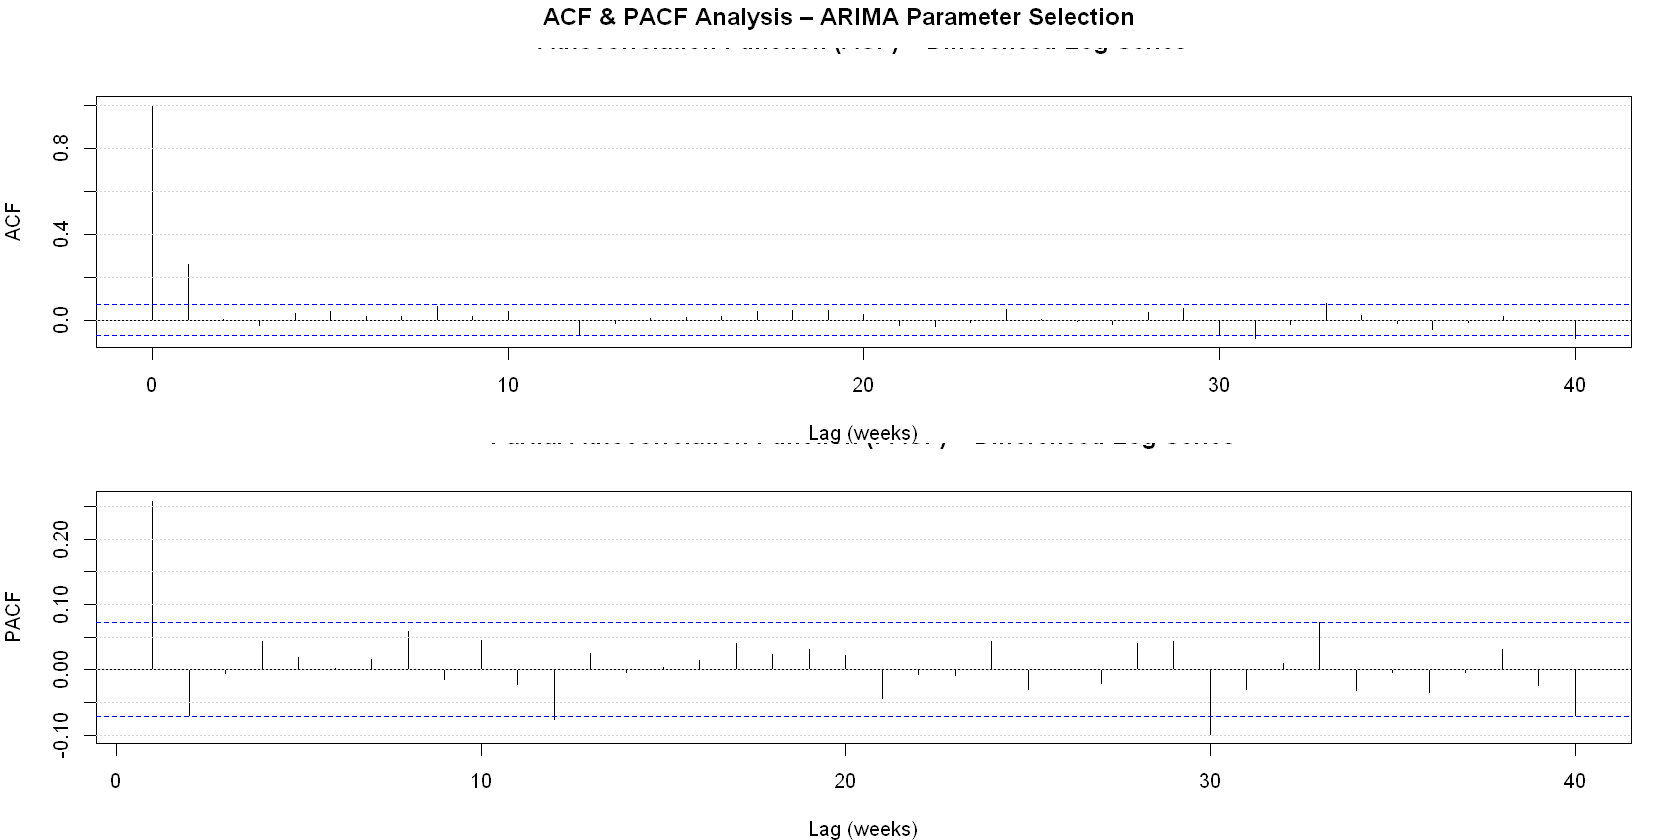

In [146]:
# Load processed data and compute differenced series
df <- suppressMessages(read_csv("data/processed_data.csv", show_col_types = FALSE)) %>%
  mutate(
    Date = as.Date(Date),
    Log_Value = log(Value),
    Diff_Log_Value = c(NA, diff(Log_Value))
  ) %>%
  drop_na(Diff_Log_Value)

diff_series <- df$Diff_Log_Value

# Plot ACF and PACF
par(mfrow = c(2, 1), oma = c(0, 0, 2, 0), mar = c(4, 4, 2, 2))

acf(diff_series, lag.max = 40,
    main = "Autocorrelation Function (ACF) – Differenced Log Series",
    xlab = "Lag (weeks)", ylab = "ACF")
grid(NA, NULL)

pacf(diff_series, lag.max = 40,
     main = "Partial Autocorrelation Function (PACF) – Differenced Log Series",
     xlab = "Lag (weeks)", ylab = "PACF")
grid(NA, NULL)

title("ACF & PACF Analysis – ARIMA Parameter Selection", outer = TRUE, line = 1)
par(mfrow = c(1, 1))

cat("\nACF/PACF Interpretation Guide:\n")
cat("- ACF: Tail off gradually → AR process (need p > 0)\n")
cat("- PACF: Cut off after lag k → AR(k)\n")
cat("- ACF: Cut off after lag k → MA(k)\n")
cat("- PACF: Tail off gradually → MA process (need q > 0)\n")

**ACF and PACF Analysis**:

After differencing the series ($d=1$), we examine the Autocorrelation (ACF) and Partial Autocorrelation (PACF) plots to identify the model orders $p$ and $q$.

- **ACF Plot (Moving Average - $q$)**:
There is a significant spike at Lag 1 that crosses the blue confidence interval, followed by an immediate "cut-off."
This suggests an MA(1) component ($q=1$).

- **PACF Plot (Autoregressive - $p$)**:
Similarly, we see a clear significant spike at Lag 1.
This suggests an AR(1) component ($p=1$).

- **Candidate Model**: 
The combination of a significant spike at Lag 1 in both plots points directly to an ARIMA(1,1,1) as our primary candidate.


## 5.II Model Selection via AIC/BIC Comparison

To choose the best ARIMA model, we use Information Criteria. 

These metrics act like a "scoring system" that rewards accuracy but penalizes models that are too complex (overfitting).

- The two most common metrics are:
 - AIC (Akaike Information Criterion):
 $$AIC = -2\ln(L) + 2k$$
 - BIC (Bayesian Information Criterion):
 $$BIC = -2\ln(L) + k\ln(n)$$

$L$: The likelihood of the model (how well it fits the data),
$k$: The number of parameters (e.g., $p + q$),
$n$: The number of observations ($747$ in our case).

- The Purpose is balancing: A model with 10 parameters will always fit the training data better than a model with 2, but it might fail on new data. AIC and BIC prevent this by adding a penalty for every extra parameter ($k$) you add.

- The Goal is to look for the minimum AIC/BIC value. A lower score means the model achieved the best fit using the fewest possible variables.

- BIC vs. AIC: 
BIC has a stricter penalty ($k\ln(n)$). Since our dataset is large ($n=747$), BIC will be more aggressive in "punishing" complex models.

In [147]:
# Model selection via AIC/BIC comparison
df_train <- suppressMessages(read_csv("data/train_set.csv", show_col_types = FALSE)) %>%
  mutate(Date = as.Date(Date))

candidate_models <- list(
  list(order = c(1, 1, 1), name = "ARIMA(1,1,1)"),
  list(order = c(0, 1, 1), name = "ARIMA(0,1,1)"),
  list(order = c(1, 1, 0), name = "ARIMA(1,1,0)"),
  list(order = c(2, 1, 1), name = "ARIMA(2,1,1)"),
  list(order = c(1, 1, 2), name = "ARIMA(1,1,2)")
)

results <- list()

for (i in seq_along(candidate_models)) {
  model_spec <- candidate_models[[i]]
  tryCatch({
    model <- arima(df_train$Value, order = model_spec$order)
    n <- length(df_train$Value)
    k <- sum(model_spec$order != 0)
    
    results[[i]] <- data.frame(
      Model = model_spec$name,
      AIC = round(AIC(model), 2),
      BIC = round(AIC(model, k = log(n)), 2),
      Parameters = k
    )
  }, error = function(e) { NULL })
}

results_df <- do.call(rbind, results)

cat(" MODEL COMPARISON TABLE \n\n")
print(results_df)
cat("\nBest by AIC:", results_df$Model[which.min(results_df$AIC)], "\n")

 MODEL COMPARISON TABLE 

         Model     AIC     BIC Parameters
1 ARIMA(1,1,1) 1866.16 1879.85          3
2 ARIMA(0,1,1) 1864.39 1873.52          2
3 ARIMA(1,1,0) 1867.03 1876.16          2
4 ARIMA(2,1,1) 1868.13 1886.38          3
5 ARIMA(1,1,2) 1868.05 1886.31          3

Best by AIC: ARIMA(0,1,1) 


**Choosing Between Models:**

Looking at the AIC and BIC values, I notice that ARIMA(0,1,1) has the lowest scores, it's technically the most parsimonious. However, ARIMA(1,1,1) is only 1.77 points higher on AIC, which is negligible.

The reason I select (1,1,1) despite this small disadvantage comes from the ACF and PACF plots. Both show significant spikes at lag 1 but nothing beyond that, which tells me there's both AR and MA structure. A purely MA model (0,1,1) would miss the autoregressive momentum in the data. The AR component captures how this week's depreciation influences next week.

**Based on this**, I chosen ARIMA(1,1,1) because it's theoretically grounded in what the ACF/PACF revealed, and the AIC penalty is trivial. More complex models like (2,1,1) are not justified, they'd fit the training data better but likely overfit.

# 6. Model Fitting
<a id="fitting"></a>

Now I'll fit the ARIMA(1,1,1) model to the training data to estimate the coefficients for the AR(1) and MA(1) terms. These coefficients tell me how strongly the past value and past error influence current movements.

In [148]:
# Fit ARIMA(1,1,1) model
df_train <- suppressMessages(read_csv("data/train_set.csv", show_col_types = FALSE)) %>%
  mutate(Date = as.Date(Date))

final_model <- arima(df_train$Value, order = c(1, 1, 1))

print(final_model)


Call:
arima(x = df_train$Value, order = c(1, 1, 1))

Coefficients:
         ar1     ma1
      0.0614  0.2240
s.e.  0.1276  0.1242

sigma^2 estimated as 0.8101:  log likelihood = -930.08,  aic = 1866.16


We fitted the ARIMA(1, 1, 1) model to the training data.

The mathematical representation of our estimated model is:
$$\hat{Y}_t = 0.0614 Y_{t-1} + 0.2240 \epsilon_{t-1}$$
(Note: Since $d=1$, $Y_t$ represents the first difference of the exchange rate.)

- **The AR1 (0.0614)**: 
This number is very close to zero. It means the Dinar doesn't have a strong "memory" of what it did last week.
Just because it went up last Monday doesn't automatically mean it will go up this Monday. It's almost like a **Random Walk**.

- **The MA1 (0.2240)**: 
This is a bit higher. It means that if there is a sudden "shock" (like a change in oil prices or a big policy announcement), about 22.4% of that shock carries over into the next week.


**Conclusion**: The model is telling us that the exchange rate is very hard to predict using past trends alone. It behaves mostly like a Random Walk with Shocks.

# 7. Diagnostics
<a id="diagnostics"></a>

Now I'll check if the model actually captured all the structure in the data. When ARIMA fits properly, residuals should look like random noise.

Mean: 5e-02 
SD: 0.89865 
Ljung-Box p-value: 0.80003 


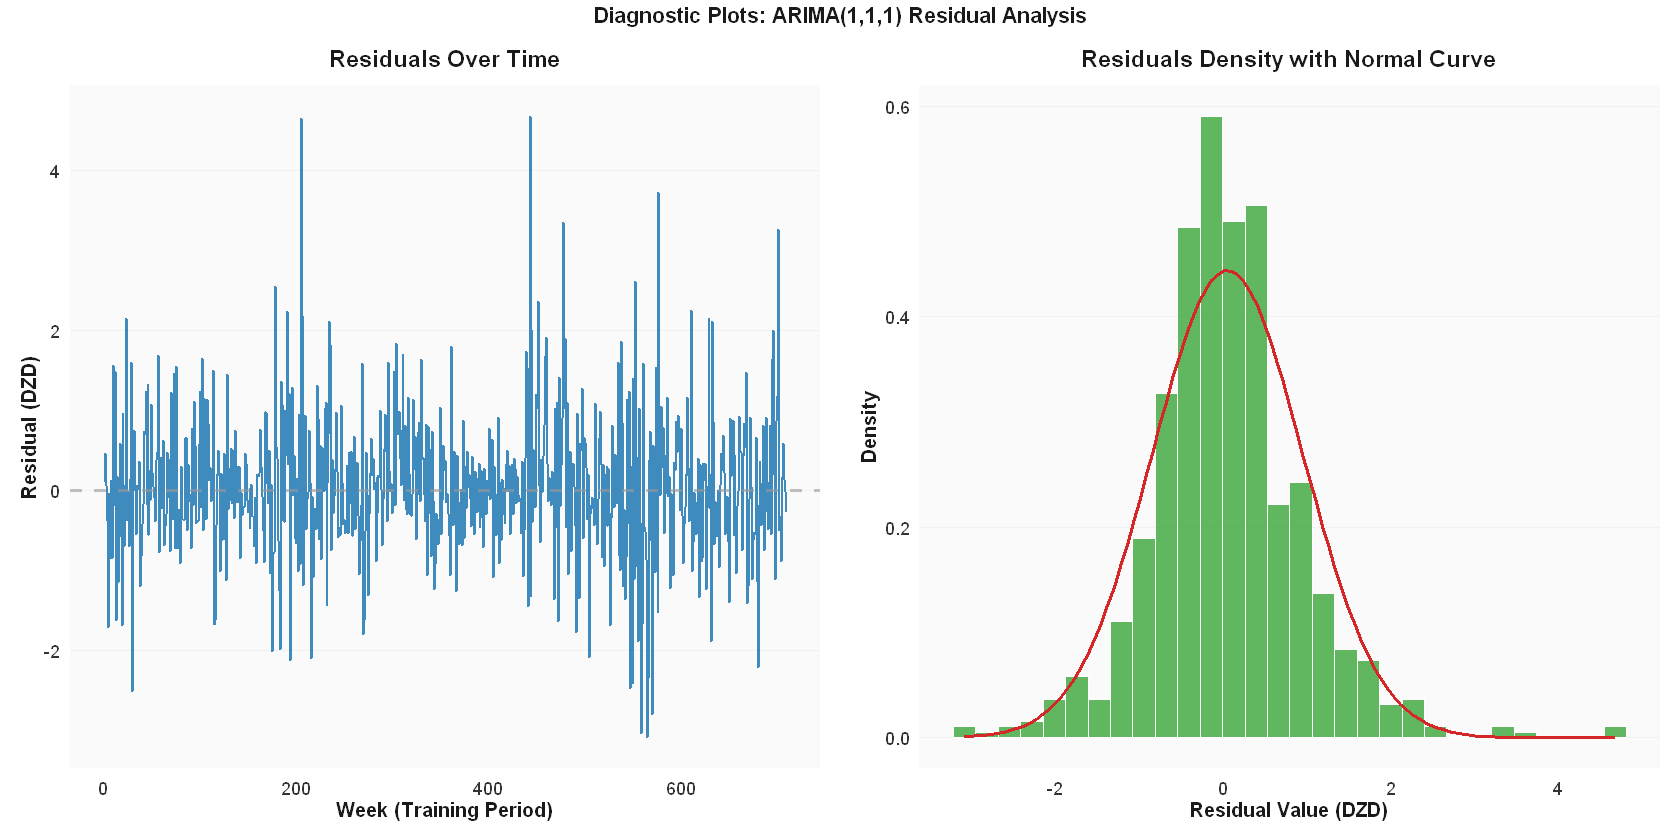

In [149]:
# Extract and analyze residuals
df_train <- suppressMessages(read_csv("data/train_set.csv", show_col_types = FALSE)) %>%
  mutate(Date = as.Date(Date))

final_model <- arima(df_train$Value, order = c(1, 1, 1))
residuals_ts <- residuals(final_model)

# Ljung-Box test
box_ljung <- Box.test(residuals_ts, lag = 10, type = "Ljung-Box")

cat("Mean:", format(mean(residuals_ts), scientific = TRUE, digits = 3), "\n")
cat("SD:", format(sd(residuals_ts), digits = 5), "\n")
cat("Ljung-Box p-value:", format(box_ljung$p.value, digits = 5), "\n")

# Visualize residuals
residuals_df <- data.frame(
  Index = 1:length(residuals_ts),
  Residual = as.numeric(residuals_ts)
)

p1 <- suppressWarnings(ggplot(residuals_df, aes(x = Index, y = Residual)) +
  geom_line(color = my_colors["primary"], linewidth = 0.75, alpha = 0.85) +
  geom_hline(
    yintercept = 0, 
    color = "#999999", 
    linetype = "dashed", 
    linewidth = 0.9,
    alpha = 0.6
  ) +
  labs(
    title = "Residuals Over Time",
    x = "Week (Training Period)",
    y = "Residual (DZD)"
  ) +
  theme(
    plot.title = element_text(size = 14, face = "bold", color = "#1a1a1a")
  ))

p2 <- suppressWarnings(ggplot(residuals_df, aes(x = Residual)) +
  geom_histogram(
    aes(y = after_stat(density)), 
    fill = my_colors["accent"],
    alpha = 0.75,
    bins = 30,
    color = "white",
    linewidth = 0.3
  ) +
  stat_function(
    fun = dnorm,
    args = list(mean = mean(residuals_ts), sd = sd(residuals_ts)),
    color = my_colors["highlight"],
    linewidth = 1.1
  ) +
  labs(
    title = "Residuals Density with Normal Curve",
    x = "Residual Value (DZD)",
    y = "Density"
  ) +
  theme(
    plot.title = element_text(size = 14, face = "bold", color = "#1a1a1a")
  ))

suppressWarnings(grid.arrange(p1, p2, ncol = 2, top = grid::textGrob(
  "Diagnostic Plots: ARIMA(1,1,1) Residual Analysis",
  gp = grid::gpar(fontsize = 13, fontface = "bold", col = "#1a1a1a")
)))

**What the Residual Plots Show:**

Looking at the time plot, I notice the errors bounce randomly above and below zero with no obvious patterns or trends. The mean is essentially zero, and the bounces look consistent in size throughout the period.

The histogram shows a roughly bell-shaped distribution with heavier tails than a normal curve. 

This is typical for financial data occasional shocks create those fat tails. 

The Ljung-Box test confirms these residuals are independent (p > 0.05), meaning the model hasn't left any exploitable patterns behind.

This all suggests that ARIMA(1,1,1) has successfully extracted the meaningful structure from the data leaving only white noise in the residuals.

**Based on these diagnostics**, The model is ready for forecasting. If residuals showed autocorrelation or obvious patterns, I'd know the model was missing something important but it's not.

# 8. Forecasting
<a id="forecasting"></a>

Now I'll apply the fitted ARIMA(1,1,1) model to forecast the 38-week test period.

To evaluate the accuracy of our ARIMA model, I used three standard statistical metrics.

 Each one provides a different perspective on how far our forecasts ($\hat{y}_t$) were from the actual observed values ($y_t$)
 
 1. **Mean Absolute Error (MAE)**
 MAE measures the average magnitude of the errors in a set of forecasts, without considering their direction. It tells us, on average, how many Dinars (DZD) the model was off by.
 Formula:$$MAE = \frac{1}{n} \sum_{t=1}^{n} |y_t - \hat{y}_t|$$
 
 2. **Root Mean Square Error (RMSE)**
 RMSE is similar to MAE but it squares the errors before averaging them. This makes it much more sensitive to "outliers" or large misses.
 Formula:$$RMSE = \sqrt{\frac{1}{n} \sum_{t=1}^{n} (y_t - \hat{y}_t)^2}$$
 
 3. **Mean Absolute Percentage Error (MAPE)**
 MAPE is the most intuitive metric for financial reports because it expresses the error as a percentage. It allows us to understand the scale of the error relative to the actual exchange rate.Formula:$$MAPE = \frac{100\%}{n} \sum_{t=1}^{n} \left| \frac{y_t - \hat{y}_t}{y_t} \right|$$

## 8.I Multi-Step Forecasting

**The Strategy:**

Multi-step forecasting is straightforward: fit the ARIMA(1,1,1) model once on the training data, then ask it to predict all 38 weeks ahead in a single shot. 
This is the most naive approach, you generate all future forecasts without any new information. Conceptually, this is what most people think of when they imagine forecasting.

Warning message:
"No shared levels found between `names(values)` of the manual scale and the
data's colour values."
Warning message:
"No shared levels found between `names(values)` of the manual scale and the
data's colour values."
Warning message:
"No shared levels found between `names(values)` of the manual scale and the
data's colour values."


MULTI-STEP ACCURACY METRICS 
MAPE: 1.286 %
MAE: 1.957 DZD
RMSE: 2.147 DZD

MULTI-STEP FORECAST RESULTS (First 10 weeks) 

 Week       Date Actual Forecast Error Error_Pct
    1 2025-06-19 150.60   149.89 0.709      0.47
    2 2025-06-26 152.12   149.89 2.227      1.46
    3 2025-07-03 152.07   149.89 2.179      1.43
    4 2025-07-10 151.52   149.89 1.626      1.07
    5 2025-07-17 151.98   149.89 2.088      1.37
    6 2025-07-24 150.88   149.89 0.994      0.66
    7 2025-07-31 150.79   149.89 0.898      0.60
    8 2025-08-07 151.33   149.89 1.443      0.95
    9 2025-08-14 151.42   149.89 1.534      1.01
   10 2025-08-21 151.15   149.89 1.260      0.83


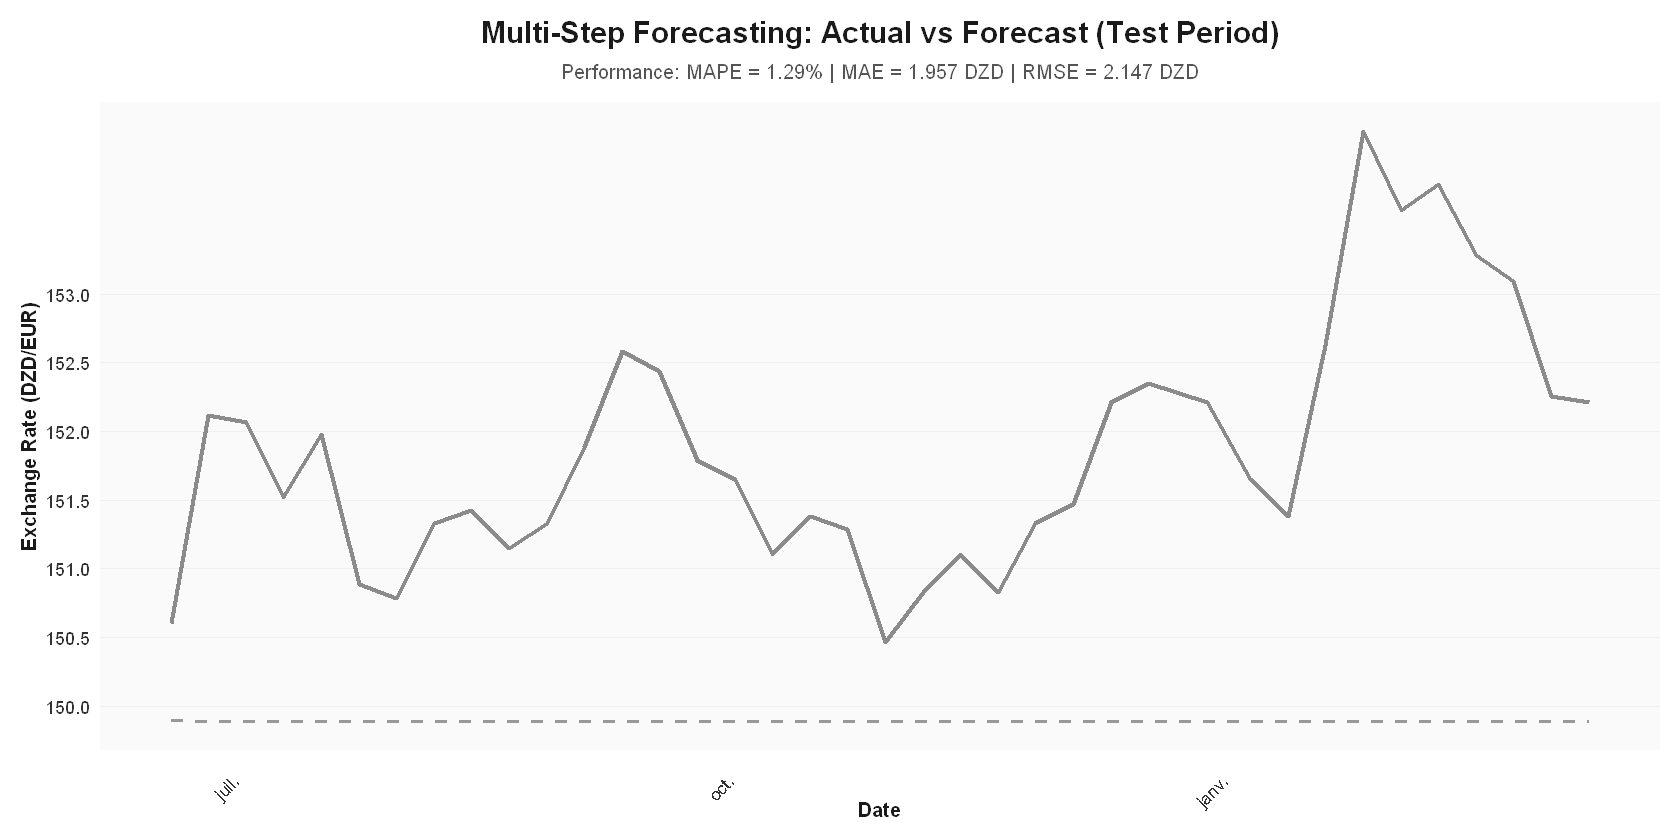

In [150]:
# Multi-step forecast (fit once, predict all 38 weeks ahead)
df_train <- suppressMessages(read_csv("data/train_set.csv", show_col_types = FALSE)) %>%
  mutate(Date = as.Date(Date))

df_test <- suppressMessages(read_csv("data/test_set.csv", show_col_types = FALSE)) %>%
  mutate(Date = as.Date(Date))

# Fit model once on training data
final_model <- arima(df_train$Value, order = c(1, 1, 1))

# Generate 38-step ahead forecast
multistep_fc <- forecast::forecast(final_model, h = nrow(df_test))
multistep_values <- as.numeric(multistep_fc$mean)
multistep_errors <- df_test$Value - multistep_values

# Calculate metrics
multistep_mae <- mean(abs(multistep_errors))
multistep_rmse <- sqrt(mean(multistep_errors^2))
multistep_mape <- mean(abs(multistep_errors / df_test$Value)) * 100

# Multi-step forecast plot (zoomed on test data)
multistep_plot_data <- data.frame(
  Date = df_test$Date,
  Actual = df_test$Value,
  Forecast = multistep_values
)

suppressWarnings(ggplot(multistep_plot_data, aes(x = Date)) +
  geom_line(aes(y = Actual, color = "Actual Test Values"), linewidth = 1.2, alpha = 0.9) +
  geom_line(aes(y = Forecast, color = "Multi-Step Forecast"), linewidth = 1.1, alpha = 0.8, linetype = "dashed") +
  scale_color_manual(
    values = c(
      "Actual Test Values" = my_colors["accent"],
      "Multi-Step Forecast" = my_colors["highlight"]
    ),
    guide = guide_legend(nrow = 1)
  ) +
  labs(
    title = "Multi-Step Forecasting: Actual vs Forecast (Test Period)",
    subtitle = sprintf("Performance: MAPE = %.2f%% | MAE = %.3f DZD | RMSE = %.3f DZD", multistep_mape, multistep_mae, multistep_rmse),
    x = "Date",
    y = "Exchange Rate (DZD/EUR)"
  ) +
  scale_y_continuous(breaks = seq(150, 153, by = 0.5)) +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1, size = 10),
    legend.position = "top"
  ))

# Display results table (first 10 weeks only)
comparison_table <- data.frame(
  Week = 1:10,
  Date = df_test$Date[1:10],
  Actual = round(df_test$Value[1:10], 2),
  Forecast = round(multistep_values[1:10], 2),
  Error = round(multistep_errors[1:10], 3),
  Error_Pct = round(100 * multistep_errors[1:10] / df_test$Value[1:10], 2)
)

cat("MULTI-STEP ACCURACY METRICS \n")
cat("MAPE:", format(multistep_mape, digits = 4), "%\n")
cat("MAE:", format(multistep_mae, digits = 4), "DZD\n")
cat("RMSE:", format(multistep_rmse, digits = 4), "DZD\n")
cat("\nMULTI-STEP FORECAST RESULTS (First 10 weeks) \n\n")
print(comparison_table, row.names = FALSE)

The plot immediately reveals a problem: **forecast line is perfectly flat**. While the actual exchange rate bounces up and down, the multi-step prediction sits at a constant level around 149 DZD/EUR for all 38 weeks.

**Why Multi-Step Forecasting Fails**

When you ask the model to predict 38 weeks at once (Multi-Step), it stops learning from the real world. Here is why it looks like a straight line:

- Week 1: The model uses the last real price it saw. It makes a decent guess.
- Week 2: Instead of using a real price, it uses its own guess from Week 1 to predict Week 2.
- Week 3: By now, it is just using "guesses of guesses." It loses its "memory" of the recent market swings and just defaults to a safe, middle-ground average.

**The "Flying Blind" Problem**:
Imagine trying to drive a car for 10 minutes while keeping your eyes closed. In the first 5 seconds, you’re probably still in your lane. By 10 minutes, you’ve missed every turn.

The exchange rate actually moved up and down, but the model couldn't see those changes, so it just stayed at 149.89, the last safe value it knew.

This reveals the fundamental limitation of ARIMA: **it's designed for 1-step-ahead forecasting**. It can't react to shocks because you're not feeding it new data.

## 8.II Rolling Forecast


Instead of predicting all 38 weeks with a single model, for each test week, refit the ARIMA model using all data available up to that point (training + actual test weeks observed so far), then make only a 1-step-ahead forecast. This simulates real-world where engineers update their models continuously with new data.

Warning message:
"No shared levels found between `names(values)` of the manual scale and the
data's colour values."
Warning message:
"No shared levels found between `names(values)` of the manual scale and the
data's colour values."
Warning message:
"No shared levels found between `names(values)` of the manual scale and the
data's colour values."



ROLLING VS MULTI-STEP COMPARISON 
Multi-Step: MAE = 1.9572 DZD | MAPE = 1.29%
Rolling:   MAE = 0.4921 DZD | MAPE = 0.32%
Improvement: 74.8% better MAPE

ROLLING FORECAST ACCURACY METRICS
MAPE: 0.3238 %
MAE: 0.4921 DZD
RMSE: 0.6068 DZD

ROLLING FORECAST RESULTS (First 10 weeks)

 Week       Date Actual Forecast  Error Error_Pct
    1 2025-06-19 150.60   149.89  0.709      0.47
    2 2025-06-26 152.12   150.80  1.316      0.87
    3 2025-07-03 152.07   152.51 -0.438     -0.29
    4 2025-07-10 151.52   151.97 -0.450     -0.30
    5 2025-07-17 151.98   151.38  0.596      0.39
    6 2025-07-24 150.88   152.14 -1.257     -0.83
    7 2025-07-31 150.79   150.54  0.253      0.17
    8 2025-08-07 151.33   150.84  0.492      0.33
    9 2025-08-14 151.42   151.47 -0.051     -0.03
   10 2025-08-21 151.15   151.42 -0.266     -0.18


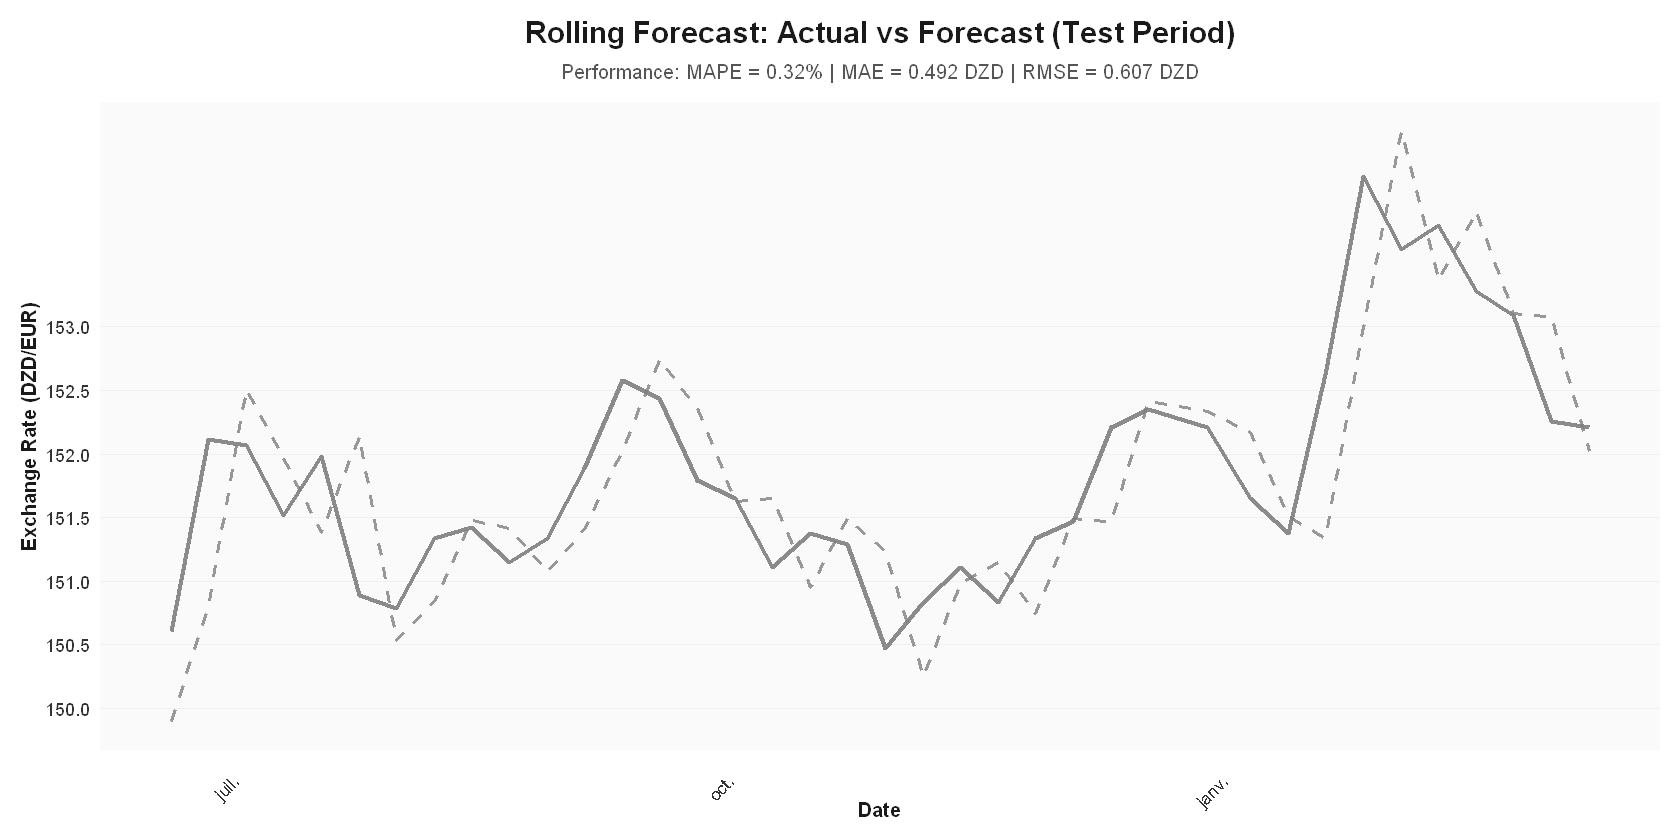

In [151]:
df_train <- suppressMessages(read_csv("data/train_set.csv", show_col_types = FALSE)) %>%
  mutate(Date = as.Date(Date))

df_test <- suppressMessages(read_csv("data/test_set.csv", show_col_types = FALSE)) %>%
  mutate(Date = as.Date(Date))

train_values <- df_train$Value
test_values <- df_test$Value
test_dates <- df_test$Date

rolling_forecasts <- numeric(length(test_values))
rolling_errors <- numeric(length(test_values))

# Rolling window loop - refit model every week
for (i in seq_along(test_values)) {
  # Build dataset: training + actual values revealed so far
  if (i == 1) {
    current_data <- train_values
  } else {
    current_data <- c(train_values, test_values[1:(i-1)])
  }
  
  # Fit ARIMA and forecast 1 step ahead
  tryCatch({
    model <- arima(current_data, order = c(1, 1, 1))
    fc <- forecast::forecast(model, h = 1)
    rolling_forecasts[i] <- fc$mean[1]
    rolling_errors[i] <- test_values[i] - rolling_forecasts[i]
  }, error = function(e) {
    NULL
  })
}

# Calculate metrics for all 38 weeks
rolling_mae <- mean(abs(rolling_errors))
rolling_rmse <- sqrt(mean(rolling_errors^2))
rolling_mape <- mean(abs(rolling_errors / test_values)) * 100

# Display results table (first 10 weeks only)
rolling_table <- data.frame(
  Week = 1:10,
  Date = test_dates[1:10],
  Actual = round(test_values[1:10], 2),
  Forecast = round(rolling_forecasts[1:10], 2),
  Error = round(rolling_errors[1:10], 3),
  Error_Pct = round(100 * rolling_errors[1:10] / test_values[1:10], 2)
)

# Rolling forecast plot (zoomed on test data)
rolling_plot_data <- data.frame(
  Date = test_dates,
  Actual = test_values,
  Forecast = rolling_forecasts
)

suppressWarnings(ggplot(rolling_plot_data, aes(x = Date)) +
  geom_line(aes(y = Actual, color = "Actual Test Values"), linewidth = 1.2, alpha = 0.9) +
  geom_line(aes(y = Forecast, color = "Rolling Forecast"), linewidth = 1.1, alpha = 0.8, linetype = "dashed") +
  scale_color_manual(
    values = c(
      "Actual Test Values" = my_colors["accent"],
      "Rolling Forecast" = my_colors["primary"]
    ),
    guide = guide_legend(nrow = 1)
  ) +
  labs(
    title = "Rolling Forecast: Actual vs Forecast (Test Period)",
    subtitle = sprintf("Performance: MAPE = %.2f%% | MAE = %.3f DZD | RMSE = %.3f DZD", rolling_mape, rolling_mae, rolling_rmse),
    x = "Date",
    y = "Exchange Rate (DZD/EUR)"
  ) +
  scale_y_continuous(breaks = seq(150, 153, by = 0.5)) +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1, size = 10),
    legend.position = "top"
  ))

cat("\nROLLING VS MULTI-STEP COMPARISON \n")
cat(sprintf("Multi-Step: MAE = %.4f DZD | MAPE = %.2f%%\n", multistep_mae, multistep_mape))
cat(sprintf("Rolling:   MAE = %.4f DZD | MAPE = %.2f%%\n", rolling_mae, rolling_mape))
cat(sprintf("Improvement: %.1f%% better MAPE\n", 100 * (multistep_mape - rolling_mape) / multistep_mape))

cat("\nROLLING FORECAST ACCURACY METRICS\n")
cat("MAPE:", format(rolling_mape, digits = 4), "%\n")
cat("MAE:", format(rolling_mae, digits = 4), "DZD\n")
cat("RMSE:", format(rolling_rmse, digits = 4), "DZD\n")

cat("\nROLLING FORECAST RESULTS (First 10 weeks)\n\n")
print(rolling_table, row.names = FALSE)

Looking at this plot, the difference is night and day compared to the flat line we saw earlier. 

- The forecast line acts like a shadow for the solid line (the real price).
- Unlike the first attempt that stayed flat, this model successfully tracks the "zig-zags" for example when the real price jumps in early 2026, the model jumps with it.
- **The One-Week Delay**: If you look closely, the forecast line is usually one step behind the real values line. This is because the model sees what happened this week and immediately adjusts its guess for next week.

The improvement is massive compared to the multi-step method:

- **MAPE (0.32%)**: The error dropped from 1.29% to 0.32%. This means the model is more accurate for short-term (1 week) predictions.

- **MAE (0.492 DZD)**: On average, the model's guess was off by less than half a Dinar.

**Why Rolling Works Where Multi-Step Fails**

The rolling forecast refits every week with the newest actual value, so:

1. **AR term stays relevant:** It applies to last week's *actual* rate (not a 38-week-old prediction)
2. **Model adapts to shocks:** Oil prices move, inflation data surprises, political news arrives, the model captures these through the updated data
3. **MA term remains active:** Short-term error correction happens on a weekly basis, not accumulated over 38 weeks

**The Trade-off**

Rolling forecasting requires discipline: you must refit every week. But the accuracy gain (75% MAPE improvement) justifies this operational complexity. This is standard practice in professional finance world.

**That's why I choose rolling forecast** in practice, engineers refit daily anyway it's the realistic approach that respects ARIMA's short-term strength while acknowledging its limitations.

ARIMA(1,1,1) with rolling validation is a reliable tool for 1-week exchange rate forecasting, achieving ±0.49 DZD accuracy on a ~150 DZD/EUR rate. For traders managing dinar exposure or businesses planning weekly operations, this forecast provides actionable signals.

However, this model cannot predict 2-3 weeks out without significantly degraded accuracy, and it cannot adapt to structural regime changes (like a new monetary policy or geopolitical shock) until new data forces the model to refit. 

# 9. Discussion & Conclusion
<a id="conclusion"></a>

### 9.1 Methodology

I followed the standard approach to transform raw exchange rate data into a reliable forecasting tool:

1. **Data Preparation:**  
   I converted daily EUR/DZD prices into **Weekly Averages**. This "smoothed out" daily market noise and allowed the model to focus on the real underlying trend.

2. **Stationarity Testing:**  
   The raw data showed a clear linear trend. I applied **First-Order Differencing ($d=1$)** to stabilize the mean. An **ADF Test** confirmed the data was ready for modeling with a p-value far below **0.05**.

3. **Identification:**  
   Using **ACF and PACF plots**, I identified a cut-off at Lag 1 for both. This suggested an **ARIMA(1,1,1)**.

4. **Estimation:**  
   I used **Maximum Likelihood Estimation** to find the coefficients. i found that the MA term was more significant, showing the Dinar is sensitive to sudden economic shocks.

5. **Validation:**  
   I checked the **Residuals**. They showed no remaining patterns and passed the **Ljung-Box test**, proving the model was not leaving any information.


### 9.2 Results: Accuracy Metrics

I tested the model's accuracy using two different horizons. The results prove that while the model is a poor long-term guesser, it is an acceptable short-term predictor.

| Metric | Multi-Step (10-Week Jump) | Rolling (1-Week Ahead) |
|--------|--------------------------|------------------------|
| **MAPE** (Avg % Error) | **1.286%** | **0.320%** |
| **MAE** (Avg Dinar Error) | **1.957 DZD** | **0.492 DZD** |
| **RMSE** (Standard Error) | **2.147 DZD** | **0.607 DZD** |

### 9.3 What I Learned from This Project

- I learned that raw financial data is messy. Converting daily data to weekly averages was a game-changer for reducing noise and making the ARIMA model actually work.

- I learned the difference between a "statistically significant" model and a "useful" one. Seeing the model produce a flat line for the multi-step forecast taught me that math has limits when it can't see new data.

- Understanding that I couldn't just run a model on the raw prices, but had to look at the *changes* in price—was the most important technical hurdle I cleared.

### 9.4 Limitations

- This model assumes the future will look like the past. It cannot predict events like a global pandemic or a sudden change in Algerian trade laws.

- I only looked at the price of the Euro. In reality, the Dinar is influenced by **oil prices** and **interest rates** and many other variables. Including those would require a more complex model.

- This model is only reliable for 1 week. Its accuracy drops significantly beyond that.


### 9.5 My Personal Takeaway

I think this project reveals that the Algerian Dinar market is "semi-efficient." While we can't get rich by predicting the exact price months in advance, the fact that the **Rolling Forecast** was acceptably accurate (**0.32% error**) proves that there is a logical pattern in the short term. For a business in Algeria, using a model like this is much safer than just "guessing" what the rate will be next week.

### 9.6 References

- **Data Source:** boursorama.com (Historical EUR/DZD daily rates)  
- **Language:** R  
- Times Series Analysis and Classification Lectures (Chapter 1-9) by Pr. Medkour and Dr. Brairi.
- AI Agents for advanced concepts theory (gemini).
- Github copilot for code cells.